# Controlling for prompt length (Llama 3.1 tokens)

**Question:** the conditions' prompts differ in length. Do the throttle differences between conditions (E vs N, M/MP vs N, M/MP vs E) survive once input length is controlled?

| condition | mean input tokens (Llama 3.1, BOS incl.) |
|---|---|
| E (emotional) | 367.6 |
| M (mechanical) = E + 8-token prefix | 375.6 |
| MP (mechanicalprime) = E + 16-token prefix | 383.6 |
| N (neutral) | 388.3 |

**Why this needs the per-prompt data.** Every recording of a condition runs the same 20 prompts, so at the recording level total input length is a *constant per condition*, perfectly confounded with condition. It cannot be adjusted statistically there. Within a condition, however, the 20 prompts differ in length (sd ≈ 24 tokens), so we can learn how throttle depends on length **prompt by prompt**, inside the same recording.

**Two approaches**
1. **Regression adjustment** (section 3–4): estimate the within-recording effect of input length on per-prompt throttle, then shift each recording's value to neutral's mean length and recompute θ.
2. **Length-matched prompt subsets** (section 5): recompute each recording's throttle from a subset of prompts chosen so the two conditions have the same mean length. No slope assumption.

**Why not control for run duration?** Section 6: duration is mostly a readout of CPU speed and tracks the outcome itself (r ≈ −0.95), so adjusting for it produces an artefactual reversal.

θ as in the other notebooks: the probability that a run of the first condition throttles more than a run of the second on the same node and date (0.5 = no difference); exact stratified permutation test, one-sided for E vs N, two-sided otherwise. Outputs go to `OUT`; inputs are read-only.

In [1]:
from pathlib import Path
import sys, json, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/features/recomputed/fulltrace").is_dir())
sys.path.insert(0, str(ROOT / "analysis/lib"))
import fulltrace_matched, fulltrace_length
importlib.reload(fulltrace_matched); importlib.reload(fulltrace_length)
from fulltrace_node_day import load_recordings
from fulltrace_matched import theta_report
from fulltrace_length import load_prompt_frame, length_slopes, adjusted_runs, matched_prompts, subset_runs

TIMEZONE = "America/Chicago"
SEED, THETA_REPEATS = 42, 20000
CONDITIONS = ("emotional", "neutral", "mechanical", "mechanicalprime")
OUTCOMES = {"PTE / cycles": "core_power.throttle__per_cycle", "PTE mean rate": "core_power.throttle__mean_rate"}
PROMPT_OUTCOMES = {"PTE / cycles": "throttle_per_cycle", "PTE mean rate": "throttle_rate"}
SUBSET_OUTCOMES = {"PTE / cycles": "per_cycle", "PTE mean rate": "mean_rate"}
MAIN_MODEL = "within recording + position trend"
OUT = ROOT / "results/fulltrace_length_control_2026-11-04"
OUT.mkdir(parents=True, exist_ok=True)
COLORS = {"emotional": "#C44E52", "neutral": "#4477AA", "mechanical": "#55A868", "mechanicalprime": "#2E7D4F"}
SHORT = {"emotional": "E", "neutral": "N", "mechanical": "M", "mechanicalprime": "MP", "transcription": "M|MP"}
pd.set_option("display.max_rows", 100)

def save_figure(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Data

- **Recordings:** all successful 70B full-trace E, N, M and MP recordings (same inclusion rules as the other notebooks).
- **Per-prompt totals:** throttle, cycles and instructions summed over each prompt's time window (`scripts/run/extract_prompt_totals_fulltrace.py`). The first ~2 s of prompt 0 precede the perf start and are not covered.
- **Check:** summing the per-prompt totals must reproduce each recording's PTE / cycles.
- **Token counts:** Llama 3.1 70B tokenizer (`unsloth/Meta-Llama-3.1-70B-Instruct`), `instructions` field, BOS included — identical to `token_counts_llama31_70b.csv` for E, N and MP, with M added. The chat template adds the same tokens to every prompt and doesn't change differences. Output length (≤ 50 tokens) is not logged and can't be controlled.

,recordings,prompt rows,"per-prompt sums / recording value (min, max)"
0,208,4160,"0.9924, 1.0000"


condition,emotional,mechanical,mechanicalprime,neutral
batch,,,,
batch_001_en,19,0,0,20
batch_003_enj,10,0,0,10
batch_004_enm,5,5,0,5
batch_005_nem,10,10,0,9
batch_007_nemp,35,0,35,35


,mean,std,min,max,sum
condition,,,,,
emotional,367.6,23.9,321,408,7352
mechanical,375.6,23.9,329,416,7512
mechanicalprime,383.6,23.9,337,424,7672
neutral,388.2,23.2,337,431,7765


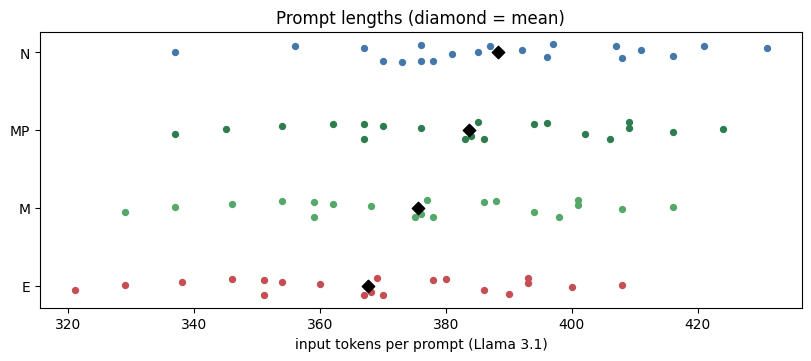

In [2]:
traces, _, _, _ = load_recordings(ROOT, TIMEZONE, conditions=CONDITIONS)
traces["node"], traces["day"] = traces.node.astype(str), traces.day.astype(str)
prompts, tokens = load_prompt_frame(ROOT)
mean_tokens = tokens.groupby("condition").n_tokens.mean()

check = prompts.groupby(["batch", "run_label"])[["core_power.throttle", "cycles"]].sum()
check = (check["core_power.throttle"] / check.cycles) / traces.set_index(["batch", "run_label"])["core_power.throttle__per_cycle"]
display(pd.DataFrame({"recordings": [len(traces)], "prompt rows": [len(prompts)],
                      "per-prompt sums / recording value (min, max)": [f"{check.min():.4f}, {check.max():.4f}"]}))
display(pd.crosstab(traces.batch, traces.condition))
display(tokens.groupby("condition").n_tokens.agg(["mean", "std", "min", "max", "sum"]).round(1))

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
for i, (cond, sub) in enumerate(tokens.groupby("condition")):
    ax.scatter(sub.n_tokens, np.full(len(sub), i) + np.random.default_rng(0).uniform(-.12, .12, len(sub)),
               color=COLORS[cond], s=18)
    ax.scatter(sub.n_tokens.mean(), i, marker="D", color="black", s=40, zorder=3)
ax.set(yticks=range(4), yticklabels=[SHORT[c] for c in sorted(tokens.condition.unique())],
       xlabel="input tokens per prompt (Llama 3.1)", title="Prompt lengths (diamond = mean)")
save_figure(fig, "prompt_lengths")

## 2. How does input length relate to throttling, within a recording?

Each point is one prompt of one recording, centred on its recording's mean (so node, date and condition drop out). The slope is estimated from **prompt-to-prompt** variation inside recordings:

> log(per-prompt throttle) = recording + b × (tokens / 100) [+ c × prompt position]

- In E, M and MP the prompt order correlates with length (r = −0.44: later prompts are shorter), so the main model adds a linear trend in **prompt position** to separate length from time-in-run.
- Prompt-position *categories* are not used: within a condition each position always has the same prompt, so they would absorb all length variation.
- E, M and MP share the same 20 texts, so their slopes are not independent evidence.
- Standard errors are clustered by prompt.

outcome,PTE / cycles,PTE mean rate
model,,
within recording,-8.80 (-12.14 to -5.32),-9.70 (-12.96 to -6.31)
within recording + position trend,-6.21 (-7.76 to -4.64),-7.46 (-9.20 to -5.68)
emotional only (+ position trend),-6.37 (-8.82 to -3.85),-7.34 (-10.01 to -4.59)
mechanical only (+ position trend),-5.74 (-8.47 to -2.92),-7.11 (-9.89 to -4.25)
mechanicalprime only (+ position trend),-6.11 (-9.06 to -3.07),-7.48 (-10.55 to -4.31)
neutral only (+ position trend),-6.24 (-9.49 to -2.88),-7.80 (-11.76 to -3.67)


For comparison, processing time: within recording: +13.6% per +100 tokens; within recording + position trend: +12.1% per +100 tokens

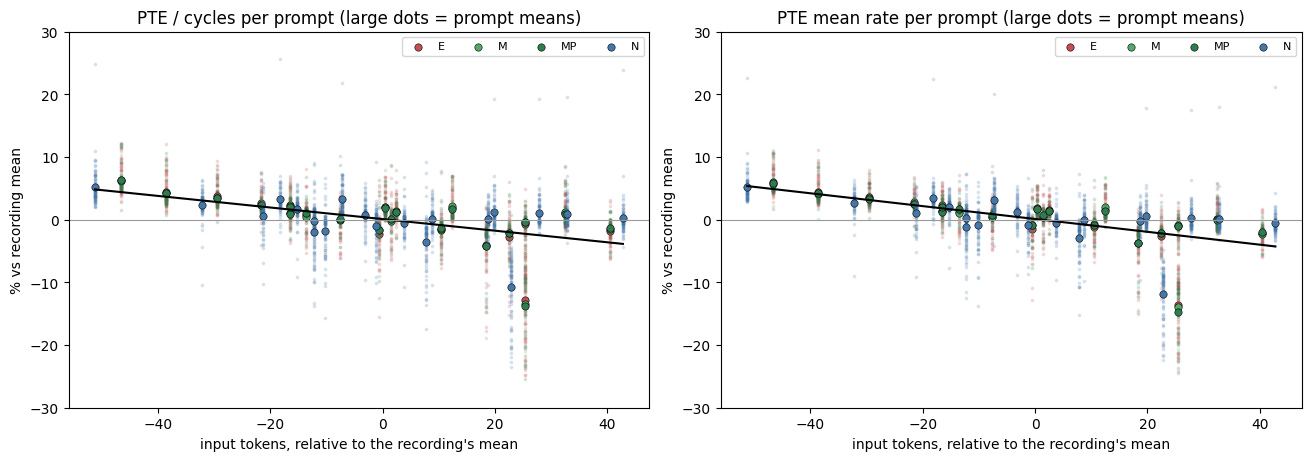

In [3]:
slopes = length_slopes(prompts, PROMPT_OUTCOMES)
slopes.to_csv(OUT / "length_slopes.csv", index=False)
display(slopes.assign(**{"% per +100 tokens (95% CI)": [f"{e:+.2f} ({lo:+.2f} to {hi:+.2f})" for e, lo, hi in zip(slopes.pct_per_100, slopes.pct_low, slopes.pct_high)]})
        .pivot_table(index="model", columns="outcome", values="% per +100 tokens (95% CI)", aggfunc="first", sort=False))
display(Markdown("For comparison, processing time: " + "; ".join(
    f"{r.model}: {r.pct_per_100:+.1f}% per +100 tokens" for r in length_slopes(prompts, {"elapsed": "elapsed_s"}).iloc[:2].itertuples())))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for ax, (name, column) in zip(axes, PROMPT_OUTCOMES.items()):
    d = prompts.assign(y=np.log(prompts[column]))
    d["y_c"] = d.y - d.groupby("run").y.transform("mean")
    d["t_c"] = d.n_tokens - d.groupby("run").n_tokens.transform("mean")
    for cond, sub in d.groupby("condition"):
        ax.scatter(sub.t_c, 100 * np.expm1(sub.y_c), s=3, alpha=.15, color=COLORS[cond])
        means = sub.groupby("prompt_index")[["t_c", "y_c"]].mean()
        ax.scatter(means.t_c, 100 * np.expm1(means.y_c), s=28, color=COLORS[cond], edgecolor="black",
                   linewidth=.4, label=SHORT[cond])
    b = slopes.loc[(slopes.outcome == name) & (slopes.model == "within recording"), "slope_log"].item()
    xs = np.linspace(d.t_c.min(), d.t_c.max(), 2)
    ax.plot(xs, 100 * np.expm1(b * xs / 100), color="black", linewidth=1.5)
    ax.axhline(0, color="#999", linewidth=.8)
    ax.set(xlabel="input tokens, relative to the recording's mean", ylabel="% vs recording mean",
           title=f"{name} per prompt (large dots = prompt means)", ylim=(-30, 30))
    ax.legend(fontsize=8, ncol=4)
save_figure(fig, "length_slope")

## 3. Length-adjusted θ (regression adjustment)

Each recording's value is shifted to neutral's mean prompt length using the main slope b:

> adjusted = value × exp(−b × (mean tokens of its condition − 388.25) / 100)

N runs are unchanged; E runs (≈ 21 tokens shorter) are lowered by ≈ |b| × 0.21; M and MP less. Then θ is recomputed. Rows with the slope at the ends of its 95% CI, and with the slope estimated without the position trend, show how much the result depends on b. The test treats b as known.

**Comparisons:** E vs N (all 38 node/dates); M vs N and M vs E (12 & 25 Oct); MP vs N and MP vs E (2 Nov); and M or MP pooled as one transcription condition (21 node/dates).

In [4]:
COMPARISONS = [("emotional", "neutral", "E vs N", "greater", False),
               ("mechanical", "neutral", "M vs N", "two-sided", False),
               ("mechanical", "emotional", "M vs E", "two-sided", False),
               ("mechanicalprime", "neutral", "MP vs N", "two-sided", False),
               ("mechanicalprime", "emotional", "MP vs E", "two-sided", False),
               ("transcription", "neutral", "M|MP vs N", "two-sided", True),
               ("transcription", "emotional", "M|MP vs E", "two-sided", True)]
pool = lambda d: d.assign(condition=d.condition.replace({"mechanical": "transcription", "mechanicalprime": "transcription"}))
everything = {"all": lambda g: g.node.notna()}

def theta_row(runs, column):
    out = {}
    for first, second, name, alternative, pooled in COMPARISONS:
        data = pool(runs) if pooled else runs
        _, r = theta_report(data, column, everything, first, second, alternative, repeats=THETA_REPEATS, seed=SEED)
        out[name] = r.iloc[0]
    return out

rows = []
for name, column in OUTCOMES.items():
    s = slopes.loc[slopes.outcome == name].set_index("model")
    variants = [("unadjusted", 0.0),
                ("adjusted, main slope", s.loc[MAIN_MODEL, "slope_log"]),
                ("adjusted, slope at CI end (weaker)", s.loc[MAIN_MODEL, "slope_high"]),
                ("adjusted, slope at CI end (stronger)", s.loc[MAIN_MODEL, "slope_low"]),
                ("adjusted, slope without position trend", s.loc["within recording", "slope_log"])]
    for variant, b in variants:
        runs = adjusted_runs(traces, column, b, mean_tokens)
        for comparison, r in theta_row(runs, column + "__length_adj").items():
            rows.append(dict(outcome=name, variant=variant, pct_per_100=100 * np.expm1(b), comparison=comparison,
                             n_groups=r.n_groups, theta_group=r.theta_group, group_low=r.group_low, group_high=r.group_high,
                             p_group=r.p_group, theta_pair=r.theta_pair, p_pair=r.p_pair))
adjusted = pd.DataFrame(rows)
adjusted.to_csv(OUT / "theta_length_adjusted.csv", index=False)

for name in OUTCOMES:
    sub = adjusted.loc[adjusted.outcome == name].copy()
    sub["cell"] = [f"{t:.2f} (p={p:.2g})" for t, p in zip(sub.theta_group, sub.p_group)]
    sub["variant"] = [f"{v} [{b:+.1f}%/100 tok]" if v != "unadjusted" else v for v, b in zip(sub.variant, sub.pct_per_100)]
    display(Markdown(f"**{name}: θ per group (exact p)** — node/dates: " + ", ".join(
        f"{c} {int(g)}" for c, g in sub.drop_duplicates("comparison")[["comparison", "n_groups"]].itertuples(index=False))))
    display(sub.pivot_table(index="variant", columns="comparison", values="cell", aggfunc="first", sort=False)
            [[c[2] for c in COMPARISONS]])

**PTE / cycles: θ per group (exact p)** — node/dates: E vs N 38, M vs N 10, M vs E 10, MP vs N 11, MP vs E 11, M|MP vs N 21, M|MP vs E 21

comparison,E vs N,M vs N,M vs E,MP vs N,MP vs E,M|MP vs N,M|MP vs E
variant,,,,,,,
unadjusted,0.69 (p=0.0005),0.70 (p=0.17),0.57 (p=0.65),0.59 (p=0.24),0.58 (p=0.3),0.64 (p=0.061),0.58 (p=0.31)
"adjusted, main slope [-6.2%/100 tok]",0.54 (p=0.26),0.68 (p=0.24),0.68 (p=0.23),0.55 (p=0.53),0.71 (p=0.0038),0.61 (p=0.15),0.70 (p=0.0074)
"adjusted, slope at CI end (weaker) [-4.6%/100 tok]",0.57 (p=0.12),0.68 (p=0.24),0.68 (p=0.23),0.57 (p=0.37),0.68 (p=0.017),0.62 (p=0.12),0.68 (p=0.016)
"adjusted, slope at CI end (stronger) [-7.8%/100 tok]",0.50 (p=0.49),0.57 (p=0.65),0.70 (p=0.16),0.55 (p=0.53),0.76 (p=0.00029),0.56 (p=0.43),0.73 (p=0.0011)
"adjusted, slope without position trend [-8.8%/100 tok]",0.47 (p=0.67),0.57 (p=0.65),0.70 (p=0.16),0.55 (p=0.53),0.77 (p=0.00016),0.56 (p=0.43),0.74 (p=0.00082)


**PTE mean rate: θ per group (exact p)** — node/dates: E vs N 38, M vs N 10, M vs E 10, MP vs N 11, MP vs E 11, M|MP vs N 21, M|MP vs E 21

comparison,E vs N,M vs N,M vs E,MP vs N,MP vs E,M|MP vs N,M|MP vs E
variant,,,,,,,
unadjusted,0.71 (p=0.00013),0.70 (p=0.17),0.55 (p=0.78),0.69 (p=0.012),0.62 (p=0.11),0.69 (p=0.0094),0.59 (p=0.25)
"adjusted, main slope [-7.5%/100 tok]",0.51 (p=0.47),0.70 (p=0.17),0.70 (p=0.16),0.63 (p=0.087),0.80 (p=2.4e-05),0.66 (p=0.03),0.75 (p=0.00032)
"adjusted, slope at CI end (weaker) [-5.7%/100 tok]",0.55 (p=0.22),0.70 (p=0.17),0.68 (p=0.23),0.64 (p=0.054),0.77 (p=0.00016),0.67 (p=0.022),0.73 (p=0.0016)
"adjusted, slope at CI end (stronger) [-9.2%/100 tok]",0.44 (p=0.85),0.68 (p=0.24),0.70 (p=0.16),0.62 (p=0.12),0.86 (p=3e-07),0.65 (p=0.054),0.78 (p=4.3e-05)
"adjusted, slope without position trend [-9.7%/100 tok]",0.44 (p=0.86),0.68 (p=0.24),0.70 (p=0.16),0.62 (p=0.12),0.87 (p=1.2e-07),0.65 (p=0.054),0.79 (p=2.9e-05)


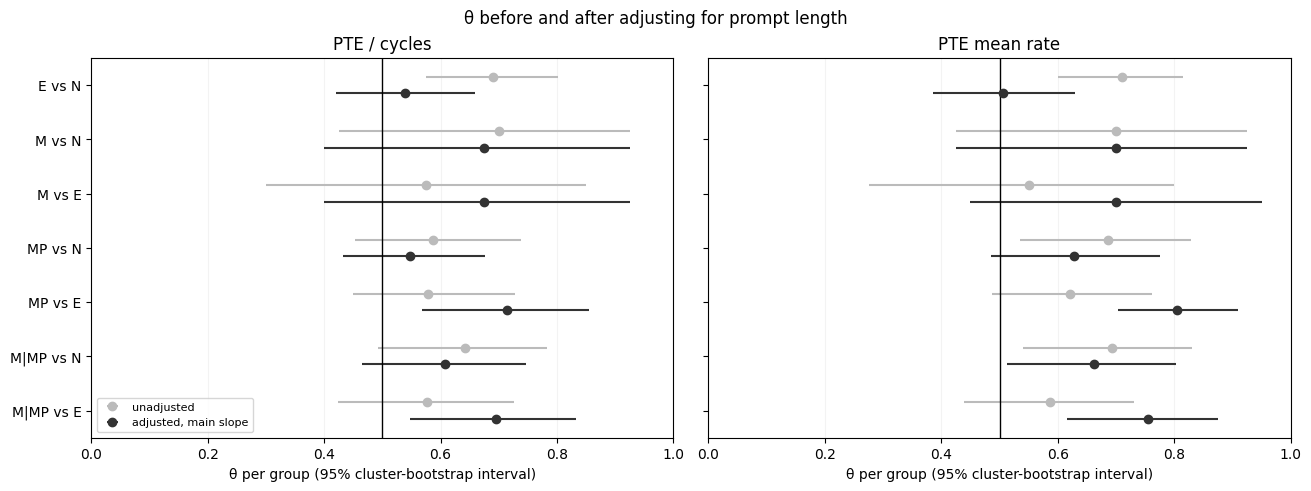

In [5]:
show = ["unadjusted", "adjusted, main slope"]
names = [c[2] for c in COMPARISONS]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, layout="constrained")
for ax, name in zip(axes, OUTCOMES):
    for k, (variant, color) in enumerate(zip(show, ["#BBBBBB", "#333333"])):
        sub = adjusted.loc[(adjusted.outcome == name) & (adjusted.variant == variant)].set_index("comparison").loc[names]
        y = np.arange(len(names)) + (k - .5) * .3
        ax.errorbar(sub.theta_group, y, xerr=[sub.theta_group - sub.group_low, sub.group_high - sub.theta_group],
                    fmt="o", color=color, ecolor=color, capsize=0, label=variant)
    ax.axvline(.5, color="black", linewidth=1)
    ax.set(yticks=range(len(names)), yticklabels=names, ylim=(len(names) - .5, -.5), xlim=(0, 1),
           xlabel="θ per group (95% cluster-bootstrap interval)", title=name)
    ax.grid(axis="x", alpha=.15)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("θ before and after adjusting for prompt length")
save_figure(fig, "theta_length_adjusted")

## 4. Length-matched prompt subsets (no slope needed)

For each pair of conditions, drop the shortest prompts of the shorter condition and the longest prompts of the longer one (alternately, keeping as many as possible) until the two sets have the same mean length. Each recording's throttle is then recomputed from its kept prompts only, and θ is recomputed on the same node/dates.

This needs no assumption about the slope, but the kept prompts are a subset chosen by length, so prompt *content* (and position) also changes. Read it as a check on section 3, not as a replacement.

In [6]:
all_prompts = list(range(20))
rows = []
for first, second, name, alternative, pooled in COMPARISONS:
    if pooled:
        continue
    shorter, longer = sorted([first, second], key=lambda c: mean_tokens[c])
    keep_s, keep_l, mean_s, mean_l = matched_prompts(tokens, shorter, longer)
    for label, keep in [("all 20 prompts", {first: all_prompts, second: all_prompts}),
                        ("length-matched", {shorter: keep_s, longer: keep_l})]:
        runs = subset_runs(prompts, keep)
        for outcome, column in SUBSET_OUTCOMES.items():
            _, r = theta_report(runs, column, everything, first, second, alternative, repeats=THETA_REPEATS, seed=SEED)
            r = r.iloc[0]
            rows.append(dict(comparison=name, prompts=label, outcome=outcome,
                             kept=f"{SHORT[shorter]} {len(keep[shorter])}, {SHORT[longer]} {len(keep[longer])}",
                             mean_tokens=f"{SHORT[shorter]} {np.mean([tokens.set_index(['condition','prompt_index']).n_tokens[(shorter, i)] for i in keep[shorter]]):.1f}, "
                                         f"{SHORT[longer]} {np.mean([tokens.set_index(['condition','prompt_index']).n_tokens[(longer, i)] for i in keep[longer]]):.1f}",
                             n_groups=r.n_groups, theta_group=r.theta_group, group_low=r.group_low,
                             group_high=r.group_high, p_group=r.p_group))
matched = pd.DataFrame(rows)
matched.to_csv(OUT / "theta_length_matched.csv", index=False)
matched["cell"] = [f"{t:.2f} ({lo:.2f}–{hi:.2f}) p={p:.2g}" for t, lo, hi, p in zip(matched.theta_group, matched.group_low, matched.group_high, matched.p_group)]
display(matched.pivot_table(index=["comparison", "prompts", "kept", "mean_tokens"], columns="outcome",
                            values="cell", aggfunc="first", sort=False))

outcome                                                                PTE / cycles  \
comparison prompts        kept        mean_tokens                                     
E vs N     all 20 prompts E 20, N 20  E 367.6, N 388.2    0.69 (0.57–0.80) p=0.0005   
           length-matched E 14, N 15  E 379.7, N 378.5      0.44 (0.32–0.57) p=0.83   
M vs N     all 20 prompts M 20, N 20  M 375.6, N 388.2      0.70 (0.42–0.93) p=0.17   
           length-matched M 17, N 17  M 382.4, N 382.2      0.70 (0.42–0.93) p=0.17   
M vs E     all 20 prompts E 20, M 20  E 367.6, M 375.6      0.57 (0.30–0.85) p=0.65   
           length-matched E 18, M 18  E 372.3, M 371.6      0.68 (0.40–0.93) p=0.23   
MP vs N    all 20 prompts MP 20, N 20 MP 383.6, N 388.2     0.59 (0.45–0.74) p=0.24   
           length-matched MP 19, N 19 MP 386.1, N 386.0     0.55 (0.43–0.68) p=0.53   
MP vs E    all 20 prompts E 20, MP 20 E 367.6, MP 383.6      0.58 (0.45–0.73) p=0.3   
           length-matched E 16, MP 16 E 376.1, MP 375.9  0.80 (0.69–0.91) p=3.2e-05   

outcome                                                               PTE mean rate  
comparison prompts        kept        mean_tokens                                    
E vs N     all 20 prompts E 20, N 20  E 367.6, N 388.2   0.71 (0.60–0.82) p=0.00013  
           length-matched E 14, N 15  E 379.7, N 378.5      0.37 (0.25–0.50) p=0.99  
M vs N     all 20 prompts M 20, N 20  M 375.6, N 388.2      0.70 (0.42–0.93) p=0.17  
           length-matched M 17, N 17  M 382.4, N 382.2      0.70 (0.42–0.93) p=0.17  
M vs E     all 20 prompts E 20, M 20  E 367.6, M 375.6      0.55 (0.28–0.80) p=0.78  
           length-matched E 18, M 18  E 372.3, M 371.6      0.70 (0.45–0.95) p=0.16  
MP vs N    all 20 prompts MP 20, N 20 MP 383.6, N 388.2    0.69 (0.53–0.83) p=0.012  
           length-matched MP 19, N 19 MP 386.1, N 386.0    0.64 (0.49–0.79) p=0.065  
MP vs E    all 20 prompts E 20, MP 20 E 367.6, MP 383.6     0.62 (0.49–0.76) p=0.11  
           length-matched E 16, MP 16 E 376.1, MP 375.9  0.88 (0.78–0.96) p=6.3e-08

## 5. Why not control for run duration instead?

Neutral runs last ≈ 2% longer than E, M and MP runs in every batch, which looks like an obvious covariate. But *within* a condition, run-to-run duration differences reflect **CPU speed**, not amount of work: duration is the inverse of instructions per second, and it tracks the throttle measure itself. Between conditions, the duration difference comes from **amount of work** (N executes more instructions because its prompts are longer), at unchanged clock frequency. A slope learnt from the first mechanism, applied to a difference caused by the second, gives a spurious result.

In [7]:
v = pd.DataFrame({"block": traces.day + "/" + traces.node, "condition": traces.condition,
                  "duration": np.log(traces.dur_s), "instructions per s": np.log(traces["instructions__mean_rate"]),
                  "total instructions": np.log(traces["instructions__mean_rate"] * traces.dur_s),
                  "cycles per s": np.log(traces["cycles__mean_rate"]),
                  "PTE / cycles": np.log(traces["core_power.throttle__per_cycle"])})
cols = ["duration", "instructions per s", "total instructions", "cycles per s", "PTE / cycles"]
within = v[cols] - v.groupby(["block", "condition"])[cols].transform("mean")
display(Markdown("**Run-to-run correlations within node/date × condition**"))
display(within.corr().round(2).loc[["duration"], cols])
cell_means = v.groupby(["block", "condition"])[cols].mean()
neutral = cell_means.xs("neutral", level="condition")
diff = pd.DataFrame({SHORT[c]: 100 * (cell_means.xs(c, level="condition") - neutral).dropna().mean()
                     for c in ["emotional", "mechanical", "mechanicalprime"]}).T
display(Markdown("**Difference from N on the same node/date (%, mean over node/dates)**"))
display(diff.round(2))
x = within.duration; slope = (x * within["PTE / cycles"]).sum() / (x * x).sum()
d = traces.assign(adj=traces["core_power.throttle__per_cycle"] * np.exp(-slope * (v.duration - v.groupby("block").duration.transform("mean"))))
_, r = theta_report(d, "adj", everything, "emotional", "neutral", "greater", repeats=THETA_REPEATS, seed=SEED)
display(Markdown(f"Duration slope within node/date × condition: {slope:.2f} (elasticity). θ for E vs N after "
                 f"adjusting PTE / cycles for duration: **{r.theta_group.iloc[0]:.2f}**, an implausible near-complete "
                 "reversal — the signature of adjusting for a proxy of the outcome."))

**Run-to-run correlations within node/date × condition**

,duration,instructions per s,total instructions,cycles per s,PTE / cycles
duration,1.0,-1.0,0.36,0.89,-0.95


**Difference from N on the same node/date (%, mean over node/dates)**

,duration,instructions per s,total instructions,cycles per s,PTE / cycles
E,-2.18,-1.50,-3.68,0.11,1.79
M,-2.16,-1.29,-3.44,0.08,1.41
MP,-1.47,-1.85,-3.32,0.55,0.43


Duration slope within node/date × condition: -3.26 (elasticity). θ for E vs N after adjusting PTE / cycles for duration: **0.02**, an implausible near-complete reversal — the signature of adjusting for a proxy of the outcome.

## 6. Conclusion

In [8]:
main = adjusted.loc[adjusted.variant.isin(["unadjusted", "adjusted, main slope"])].set_index(["outcome", "variant", "comparison"])
mt = matched.set_index(["outcome", "prompts", "comparison"])
lines = []
for name in OUTCOMES:
    b = slopes.loc[(slopes.outcome == name) & (slopes.model == MAIN_MODEL)].iloc[0]
    lines.append(f"**{name}.** Within recordings, +100 input tokens go with **{b.pct_per_100:+.1f}%** throttle "
                 f"(95% CI {b.pct_low:+.1f} to {b.pct_high:+.1f}).")
    for comparison in ["E vs N", "MP vs N", "MP vs E", "M|MP vs N", "M|MP vs E"]:
        raw, adj = main.loc[(name, "unadjusted", comparison)], main.loc[(name, "adjusted, main slope", comparison)]
        text = (f"- {comparison}: θ {raw.theta_group:.2f} (p = {raw.p_group:.2g}) → length-adjusted **{adj.theta_group:.2f}** "
                f"(p = {adj.p_group:.2g})")
        if (name, "length-matched", comparison) in mt.index:
            m = mt.loc[(name, "length-matched", comparison)]
            text += f"; length-matched prompts **{m.theta_group:.2f}** (p = {m.p_group:.2g})"
        lines.append(text)
display(Markdown("\n".join(lines)))

**PTE / cycles.** Within recordings, +100 input tokens go with **-6.2%** throttle (95% CI -7.8 to -4.6).
- E vs N: θ 0.69 (p = 0.0005) → length-adjusted **0.54** (p = 0.26); length-matched prompts **0.44** (p = 0.83)
- MP vs N: θ 0.59 (p = 0.24) → length-adjusted **0.55** (p = 0.53); length-matched prompts **0.55** (p = 0.53)
- MP vs E: θ 0.58 (p = 0.3) → length-adjusted **0.71** (p = 0.0038); length-matched prompts **0.80** (p = 3.2e-05)
- M|MP vs N: θ 0.64 (p = 0.061) → length-adjusted **0.61** (p = 0.15)
- M|MP vs E: θ 0.58 (p = 0.31) → length-adjusted **0.70** (p = 0.0074)
**PTE mean rate.** Within recordings, +100 input tokens go with **-7.5%** throttle (95% CI -9.2 to -5.7).
- E vs N: θ 0.71 (p = 0.00013) → length-adjusted **0.51** (p = 0.47); length-matched prompts **0.37** (p = 0.99)
- MP vs N: θ 0.69 (p = 0.012) → length-adjusted **0.63** (p = 0.087); length-matched prompts **0.64** (p = 0.065)
- MP vs E: θ 0.62 (p = 0.11) → length-adjusted **0.80** (p = 2.4e-05); length-matched prompts **0.88** (p = 6.3e-08)
- M|MP vs N: θ 0.69 (p = 0.0094) → length-adjusted **0.66** (p = 0.03)
- M|MP vs E: θ 0.59 (p = 0.25) → length-adjusted **0.75** (p = 0.00032)

**Reading the results**
- If E vs N falls to ≈ 0.5 after adjustment *and* on length-matched prompts, the original E > N difference is explained by the neutral prompts being longer, not by emotional content.
- If MP (or M) vs E rises above 0.5, the transcription instruction throttles *more* than the emotional prompt at equal length — the opposite of attenuation.

**Limits**
- The length slope comes from prompt-to-prompt variation *within* conditions, where length is mixed with prompt content; the adjustment assumes the same relation holds between conditions. The length-matched check doesn't need that assumption but changes which prompts are compared.
- E, M and MP share the same texts, so their slopes are not independent; N's slope alone is weaker.
- Prompt position is controlled with a linear trend only.
- Output length (≤ 50 generated tokens per prompt) is not logged and is not controlled.
- The permutation p-values treat the slope as known; the slope-sensitivity rows show the range.
- The analysis was designed after seeing the run-level results: treat it as exploratory, and a reason to run a **length-matched prompt set** in the next campaign.